# Natural Language Processing in Finance
A Data-Driven Tour of the Model Frameworks

Natural Language Processing in Finance: A Practical, Data-Driven Tour of the Model Frameworks

In finance the raw material of many decisions is text: filings, earnings-call transcripts, central-bank statements and news. This notebook takes a rigorously practical approach and walks, framework by framework, from simple word counts up to large language models and agents. For every framework we follow the following recipe for machine-learning models:

1) Importing the model class,
2) Instantiating a model object,
3) Fitting the model object to some data,
4) Predicting the outcome given the fitted model.
 
We handcraft the text data in this notebook to have more control over the results.

**Imports and configuration**
First, some standard imports and configuration.


In [10]:
import numpy as np
import pandas as pd
from pylab import mpl, plt

plt.style.use('seaborn-v0_8' if 'seaborn-v0_8' in plt.style.available else 'default')
mpl.rcParams['font.family'] = 'serif'
np.random.seed(1000)
np.set_printoptions(suppress=True, precision=4)
%matplotlib inline

In [30]:
def make_financial_corpus(n_per_class=220, seed=1000):
    """A reproducible, embedded financial-sentiment corpus (fallback).

    Short headline-style sentences with a binary label: 1 = positive tone,
    0 = negative tone. Built from templates so it is varied but deterministic.
    """
    rng = np.random.default_rng(seed)
    firms = ['Apple', 'Microsoft', 'Toyota', 'Pfizer', 'Shell', 'Nestle',
                'Siemens', 'Boeing', 'Intel', 'Daimler', 'Unilever', 'Sony']
    metrics = ['revenue', 'earnings', 'margins', 'guidance', 'demand',
                'orders', 'cash flow', 'profit']
    pos_tmpl = [
        '{f} reported record {m} and raised full-year guidance',
        '{f} beat estimates as {m} grew strongly this quarter',
        'strong {m} drove {f} shares higher after the update',
        '{f} lifted its outlook on robust {m} and improving demand',
        'analysts upgraded {f} citing accelerating {m} and new orders',
        '{f} posted better than expected {m} and announced a buyback',
    ]
    neg_tmpl = [
        '{f} cut its outlook as {m} declined sharply this quarter',
        '{f} missed estimates on weak {m} and falling demand',
        'a profit warning hit {f} after {m} deteriorated',
        '{f} shares fell as {m} disappointed and costs rose',
        'analysts downgraded {f} on shrinking {m} and litigation risk',
        '{f} reported a widening loss and an impairment on {m}',
    ]
    texts, labels = [], []
    for _ in range(n_per_class):
        f = rng.choice(firms); m = rng.choice(metrics)
        texts.append(rng.choice(pos_tmpl).format(f=f, m=m)); labels.append(1)
        f = rng.choice(firms); m = rng.choice(metrics)
        texts.append(rng.choice(neg_tmpl).format(f=f, m=m)); labels.append(0)
    # Inject ~15% "hard" ambiguous headlines that mix positive and negative
    # cues, so the data is NOT perfectly separable (realistic Bayes error).
    mixed_tmpl = [
        '{f} beat on {m} but cut guidance on weak demand',
        '{f} missed {m} yet raised its outlook on strong orders',
        'despite a loss, {f} reported improving {m} and higher orders',
        '{f} grew {m} but warned on rising costs and litigation risk',
    ]
    n_hard = int(0.15 * len(texts))
    for _ in range(n_hard):
        f = rng.choice(firms); m = rng.choice(metrics)
        texts.append(rng.choice(mixed_tmpl).format(f=f, m=m))
        labels.append(int(rng.random() < 0.5))      # genuinely ambiguous label

    idx = rng.permutation(len(texts))
    texts = [texts[i] for i in idx]; labels = np.array(labels)[idx]
    return texts, labels, ['negative', 'positive'], 'embedded-financial'


In [32]:
texts, y, target_names, source = make_financial_corpus()
print('data source :', source)
print('documents   :', len(texts))
print('classes     :', target_names, '-> counts', np.bincount(y))

data source : embedded-financial
documents   : 506
classes     : ['negative', 'positive'] -> counts [253 253]


Before any modelling, look at the data. As in the book, we load the raw sample into a pandas DataFrame and
inspect its head — this is the single most effective guard against silently feeding the wrong thing into a pipeline.
Each row is one document (a short headline) with its integer label and human-readable class name.


In [33]:
# Assemble the raw corpus into a DataFrame and inspect the head.
corpus = pd.DataFrame({'label': y,
                        'class': [target_names[t] for t in y],
                        'n_chars': [len(t) for t in texts],
                        'text': texts})
corpus.head(8)

,label,class,n_chars,text
0,0,negative,63,Daimler cut its outlook as orders declined sha...
1,0,negative,71,analysts downgraded Unilever on shrinking cash...
2,1,positive,65,Boeing lifted its outlook on robust guidance a...
3,1,positive,54,Toyota beat on revenue but cut guidance on wea...
4,0,negative,52,Apple beat on orders but cut guidance on weak ...
5,0,negative,69,analysts downgraded Microsoft on shrinking ord...
6,1,positive,69,analysts upgraded Siemens citing accelerating ...
7,1,positive,69,analysts upgraded Boeing citing accelerating c...


In [34]:
# Class balance and basic length statistics of the documents.
print('class balance:')
print(corpus['class'].value_counts(), end='\n\n')
print('document length (characters):')
print(corpus['n_chars'].describe().round(1))

class balance:
class
negative    253
positive    253
Name: count, dtype: int64

document length (characters):
count    506.0
mean      61.5
std        4.7
min       51.0
25%       58.0
50%       61.0
75%       65.0
max       72.0
Name: n_chars, dtype: float64


## Framework 1 — Classical Representations: From Text to Numbers
A model cannot consume a string; it needs numbers. The bag-of-words model fixes a vocabulary $V=\{w_1,\ldots,w_{|V|}\}$
and turns a document $d$ into a count vector $x_d\in\mathbb{R}^{|V|}$ with $x_{d,j}=\operatorname{tf}(w_j,d)$. Stacking $N$ documents gives a sparse
term-document matrix $X\in\mathbb{R}^{N\times|V|}$.

**From raw counts to TF-IDF, step by step**
Raw counts over-weight ubiquitous words ("the", "and"), so scikit-learn re-weights them with TF-IDF in
three stages:

1. Term frequency (TF). The raw count of term $t$ in document $d$ is $\operatorname{tf}(t,d)=\text{count of }t\text{ in }d$.
(With `sublinear_tf=True`, as we use below, this is dampened to $1+\log(\operatorname{tf}(t,d))$ so a word appearing 10




times is not treated as 10× as important as one appearing once.)

2. Inverse document frequency (IDF). How rare a term is across the corpus. scikit-learn's smoothed
definition (its `idf_` attribute) is $\operatorname{idf}(t)=\ln\left(\frac{1+N}{1+\operatorname{df}(t)}\right)+1$, where $N$ is the number of documents and
$\operatorname{df}(t)$ is the number of documents containing $t$. The two $+1$ terms ("smooth_idf") prevent division by
zero and stop a term that appears everywhere from collapsing to exactly zero. Rare, distinctive terms get a high
idf; ubiquitous terms get idf close to 1.

3. Combine and L2-normalise. The raw weight is the product $w(t,d)=\operatorname{tf}(t,d)\operatorname{idf}(t)$, and each document row
is then scaled to unit Euclidean length (norm='l2', the default): $\widehat{w}_d=\frac{w_d}{\lVert w_d\rVert_2}=\frac{w_d}{\sqrt{\sum_j w(t_j,d)^2}}$.
Unit-length rows are what make cosine similarity reduce to a plain dot product.

scikit-learn exposes both representations as transformers with the familiar fit/transform API.


In [35]:
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

count_vec = CountVectorizer(stop_words='english', min_df=3)               # instantiate
X_counts = count_vec.fit_transform(texts)                                 # fit + transform
X_counts.shape

(506, 72)

In [36]:
tfidf_vec = TfidfVectorizer(stop_words='english', min_df=3, sublinear_tf=True)
X_tfidf = tfidf_vec.fit_transform(texts)
X_tfidf.shape

(506, 72)

In [37]:
# The term-document matrix is extremely sparse: most entries are zero.
density = X_tfidf.nnz / (X_tfidf.shape[0] * X_tfidf.shape[1])
print(f'vocabulary size |V| : {len(tfidf_vec.vocabulary_)}')
print(f'matrix density      : {density:.4f} ({1 - density:.2%} zeros)')

vocabulary size |V| : 72
matrix density      : 0.0980 (90.20% zeros)


In [38]:
# The highest-IDF (most document-specific) terms carry the discriminative signal.
import numpy as np
feature_names = np.array(tfidf_vec.get_feature_names_out()
                        if hasattr(tfidf_vec, 'get_feature_names_out')
                        else tfidf_vec.get_feature_names())
idf = tfidf_vec.idf_
order = np.argsort(idf)
print('Lowest-IDF (ubiquitous):', list(feature_names[order[:8]]))
print('Highest-IDF (specific) :', list(feature_names[order[-8:]]))

Lowest-IDF (ubiquitous): ['demand', 'orders', 'guidance', 'profit', 'outlook', 'reported', 'shares', 'earnings']
Highest-IDF (specific) : ['upgraded', 'impairment', 'widening', 'sharply', 'declined', 'despite', 'rising', 'warned']


To make the representation concrete, here is the head of the term-document matrix itself: rows are
documents, columns are vocabulary terms, and each cell holds the (L2-normalised) TF-IDF weight w(t,d).



Almost every cell is zero — a document only touches a handful of the vocabulary — which is exactly the
sparsity we measured above.


In [39]:
# Densify a small corner of the matrix just for display (never do this at scale).
show_terms = list(feature_names[order[-10:]])           # 10 most-specific terms
col_idx = [tfidf_vec.vocabulary_[w] for w in show_terms]
tdm_head = pd.DataFrame(np.round(X_tfidf[:6, col_idx].toarray(), 3),
                        columns=show_terms)
tdm_head.insert(0, 'class', [target_names[t] for t in y[:6]])
tdm_head.head(6)

,class,citing,accelerating,upgraded,impairment,widening,sharply,declined,despite,rising,warned
0,negative,0.0,0.0,0.0,0.0,0.0,0.444,0.444,0.0,0.0,0.0
1,negative,0.0,0.0,0.0,0.0,0.0,0.000,0.000,0.0,0.0,0.0
2,positive,0.0,0.0,0.0,0.0,0.0,0.000,0.000,0.0,0.0,0.0
3,positive,0.0,0.0,0.0,0.0,0.0,0.000,0.000,0.0,0.0,0.0
4,negative,0.0,0.0,0.0,0.0,0.0,0.000,0.000,0.0,0.0,0.0
5,negative,0.0,0.0,0.0,0.0,0.0,0.000,0.000,0.0,0.0,0.0


In [40]:
# Map the first sparse document row to a dense 1-D numpy vector and inspect it.
vec = X_tfidf[0].toarray().ravel()           # shape (|V|,), mostly zeros
nz = np.nonzero(vec)[0]
print(f'document 0 : "{texts[0][:70]}"')
print(f'class       : {target_names[y[0]]}')
print(f'vector      : length {vec.shape[0]}, {len(nz)} non-zero, '
        f'||vec|| = {np.linalg.norm(vec):.3f} (unit length by L2 norm)\n')
pd.DataFrame({'term': feature_names[nz], 'tfidf_weight': np.round(vec[nz], 3)}
                ).sort_values('tfidf_weight', ascending=False).head(10)

document 0 : "Daimler cut its outlook as orders declined sharply this quarter"
class       : negative
vector      : length 72, 7 non-zero, ||vec|| = 1.000 (unit length by L2 norm)



,term,tfidf_weight
2,declined,0.444
6,sharply,0.444
0,cut,0.393
1,daimler,0.391
5,quarter,0.353
4,outlook,0.319
3,orders,0.271


A worked micro-example. Suppose the vocabulary is only ["bank", "profit", "the"], there are N=3
documents, and the three terms appear in 1, 2 and 3 of them respectively. The smoothed IDFs are

$\operatorname{idf}(\text{bank})=\ln\left(\frac{4}{2}\right)+1\approx1.693,\quad \operatorname{idf}(\text{profit})=\ln\left(\frac{4}{3}\right)+1\approx1.288,\quad \operatorname{idf}(\text{the})=\ln\left(\frac{4}{4}\right)+1=1.000$.

For a document "bank profit profit the" (counts 1, 2, 1) the raw weights are [1.693, 2.576, 1.000]; dividing by
their norm $\approx 3.240$ gives the final unit vector $[0.523, 0.795, 0.309]$. "profit" dominates — frequent here and
reasonably rare corpus-wide — while "the" is pushed toward the idf floor of 1.


In [41]:
# The same worked example, computed explicitly to match scikit-learn.
N = 3
df_counts = {'bank': 1, 'profit': 2, 'the': 3}      # docs containing each term
idf_ex = {t: np.log((1 + N) / (1 + df)) + 1 for t, df in df_counts.items()}
tf_ex = {'bank': 1, 'profit': 2, 'the': 1}          # counts in this document
raw = np.array([tf_ex[t] * idf_ex[t] for t in df_counts])
unit = raw / np.linalg.norm(raw)
pd.DataFrame({'term': list(df_counts),
                'idf': np.round(list(idf_ex.values()), 3),
                'raw_tfidf': np.round(raw, 3),
                'l2_normalised': np.round(unit, 3)})

,term,idf,raw_tfidf,l2_normalised
0,bank,1.693,1.693,0.523
1,profit,1.288,2.575,0.795
2,the,1.000,1.000,0.309


**Cosine similarity between two documents**
Cosine similarity turns the vectors into geometry — it is the cosine of the angle between two document
vectors, $\operatorname{cos}(x,y)=\frac{x^\top y}{\lVert x\rVert_2\lVert y\rVert_2}=\frac{\sum_j x_jy_j}{\sqrt{\sum_j x_j^2}\sqrt{\sum_j y_j^2}}$. It ranges over $[-1,1]$ in
general, but over $[0,1]$ for TF-IDF because all entries are non-negative: $1$ means the two texts share the same
weighted-term profile (parallel vectors), $0$ means they share no terms (orthogonal). Because `scikit-learn`
already L2-normalises every row, the denominator is 1 and the similarity is just the **dot product** $x^\top y$.

`cosine_similarity(A, B)` returns a matrix of all pairwise similarities between the rows of `A` and the rows of
`B`. Comparing one document (shape $(1, |V|)$) to five others (shape $(5, |V|)$) yields a $(1,5)$ matrix, so we
call `.ravel()` to flatten it to a one-dimensional array of five scalars for easy iteration. In finance this powers the
year-over-year 10-K textual-change signal (Cohen et al., 2020): low similarity between consecutive filings flags
large textual change.


In [43]:
from sklearn.metrics.pairwise import cosine_similarity

# Similarity of the first document to the next five.
sims = cosine_similarity(X_tfidf[0], X_tfidf[1:6]).ravel()
for j, s in enumerate(sims, start=1):
    print(f'cos(doc0, doc{j}) = {s:.3f}   [{target_names[y[j]]}]                {texts[j][:55]}')

cos(doc0, doc1) = 0.000   [negative]                analysts downgraded Unilever on shrinking cash flow and
cos(doc0, doc2) = 0.108   [positive]                Boeing lifted its outlook on robust guidance and improv
cos(doc0, doc3) = 0.168   [positive]                Toyota beat on revenue but cut guidance on weak demand
cos(doc0, doc4) = 0.253   [negative]                Apple beat on orders but cut guidance on weak demand
cos(doc0, doc5) = 0.078   [negative]                analysts downgraded Microsoft on shrinking orders and l


## Framework 2 — Lexicons, Sentiment and Classical Classifiers
The dictionary method is the honest baseline: no fitted parameters, trivially point-in-time. With
positive/negative word counts the tone of a document is

$\operatorname{tone}(d)=\frac{n_+(d)-n_-(d)}{n_+(d)+n_-(d)}$.

A general-purpose dictionary mislabels finance-neutral words ("liability", "cost"), which is why Loughran &
McDonald (2011) built a finance-specific list. Below is a compact LM-style lexicon.


In [44]:
LM_POS = {'strong', 'record', 'beat', 'raised', 'growth', 'profit', 'upgraded',
            'robust', 'higher', 'better', 'buyback', 'improving', 'accelerating'}
LM_NEG = {'cut', 'weak', 'missed', 'declined', 'falling', 'loss', 'warning',
            'downgraded', 'impairment', 'litigation', 'fell', 'disappointed', 'risk'}

def lm_tone(doc):
    toks = doc.lower().split()
    npos = sum(t in LM_POS for t in toks)
    nneg = sum(t in LM_NEG for t in toks)
    return (npos - nneg) / (npos + nneg) if (npos + nneg) else 0.0

tone = np.array([lm_tone(t) for t in texts])
pred_lex = (tone > 0).astype(int)
from sklearn.metrics import accuracy_score
print(f'dictionary-tone accuracy: {accuracy_score(y, pred_lex):.3f}')

dictionary-tone accuracy: 0.931


It helps to see the signal the dictionary produces. The head below shows, per document, the positive and
negative word counts, the resulting tone score and the predicted versus true class — the raw material the rule
above thresholds at zero.


In [45]:
def _counts(doc):
    toks = doc.lower().split()
    return sum(t in LM_POS for t in toks), sum(t in LM_NEG for t in toks)

npos, nneg = zip(*[_counts(t) for t in texts])
tone_df = pd.DataFrame({'n_pos': npos, 'n_neg': nneg,
                        'tone': np.round(tone, 2),
                        'pred': [target_names[p] for p in pred_lex],
                        'true': [target_names[t] for t in y],
                        'text': [t[:50] for t in texts]})
tone_df.head(8)

,n_pos,n_neg,tone,pred,true,text
0,0,2,-1.00,negative,negative,Daimler cut its outlook as orders declined sha...
1,0,3,-1.00,negative,negative,analysts downgraded Unilever on shrinking cash...
2,2,0,1.00,positive,positive,Boeing lifted its outlook on robust guidance a...
3,1,2,-0.33,negative,positive,Toyota beat on revenue but cut guidance on wea...
4,1,2,-0.33,negative,negative,Apple beat on orders but cut guidance on weak ...
5,0,3,-1.00,negative,negative,analysts downgraded Microsoft on shrinking ord...
6,2,0,1.00,positive,positive,analysts upgraded Siemens citing accelerating ...
7,2,0,1.00,positive,positive,analysts upgraded Boeing citing accelerating c...


Now the supervised route. Exactly as the book applies Gaussian Naive Bayes, logistic regression, decision
trees and SVMs to its sample data, we apply their text-appropriate cousins to the TF-IDF features, using a
proper train/test split.

Multinomial Naive Bayes models a document as a bag of term draws and picks the class maximising the
posterior $\hat{c}=\arg\max_c\left[\log P(c)+\sum_t x_t\log P(t\mid c)\right],\qquad P(t\mid c)=\frac{N_{tc}+\alpha}{\sum_{t'}N_{t'c}+\alpha|V|}$, where $N_{tc}$ is the
count of term $t$ in class $c$, and $\alpha$ is Laplace smoothing. **Logistic regression** instead fits weights directly,
$P(c=1\mid x)=\sigma(w^\top x+b)$, and its coefficients are readable word importances. A linear SVM
maximises the classification margin.


In [46]:
from sklearn.model_selection import train_test_split

Xtr, Xte, ytr, yte = train_test_split(X_tfidf, y, test_size=0.33, random_state=0)
Xtr.shape, Xte.shape

((339, 72), (167, 72))

In [47]:
from sklearn.naive_bayes import MultinomialNB

model = MultinomialNB()            # instantiate
model.fit(Xtr, ytr)                # fit
pred = model.predict(Xte)          # predict
print(f'Multinomial Naive Bayes accuracy: {accuracy_score(yte, pred):.3f}')

Multinomial Naive Bayes accuracy: 0.922


In [48]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(C=5, max_iter=1000)
model.fit(Xtr, ytr)
pred = model.predict(Xte)
print(f'Logistic regression accuracy    : {accuracy_score(yte, pred):.3f}')

Logistic regression accuracy    : 0.928


In [49]:
from sklearn.svm import LinearSVC

model = LinearSVC(C=1)
model.fit(Xtr, ytr)
pred = model.predict(Xte)
print(f'Linear SVM accuracy                    : {accuracy_score(yte, pred):.3f}')

Linear SVM accuracy                    : 0.928


Collecting the scores into one table makes the comparison explicit — the book's habit of tabulating models side
by side. The dictionary baseline is unsupervised and point-in-time; the supervised models trade a little
interpretability for accuracy on held-out data.


In [50]:
from sklearn.metrics import f1_score

def _fit_eval(estimator):
    estimator.fit(Xtr, ytr)
    p = estimator.predict(Xte)
    return accuracy_score(yte, p), f1_score(yte, p)

results = []
for name, est in [('Multinomial NB', MultinomialNB()),
                    ('Logistic Reg.', LogisticRegression(C=5, max_iter=1000)),
                    ('Linear SVM', LinearSVC(C=1))]:
    acc, f1 = _fit_eval(est)
    results.append({'model': name, 'accuracy': round(acc, 3), 'f1': round(f1, 3)})
results.insert(0, {'model': 'Dictionary (LM)',
                    'accuracy': round(accuracy_score(y, pred_lex), 3),
                    'f1': round(f1_score(y, pred_lex), 3)})
pd.DataFrame(results)

,model,accuracy,f1
0,Dictionary (LM),0.931,0.932
1,Multinomial NB,0.922,0.922
2,Logistic Reg.,0.928,0.927
3,Linear SVM,0.928,0.927


In [51]:
# A sparse logistic model lets us READ which words drive each class.
clf = LogisticRegression(C=5, max_iter=1000).fit(X_tfidf, y)
coef = clf.coef_[0]
order = np.argsort(coef)
print('Most negative words:', list(feature_names[order[:8]]))
print('Most positive words:', list(feature_names[order[-8:]][::-1]))

Most negative words: ['missed', 'falling', 'sharply', 'declined', 'loss', 'impairment', 'widening', 'shrinking']
Most positive words: ['beat', 'robust', 'lifted', 'year', 'record', 'grew', 'strongly', 'update']


Evaluation done right. Accuracy alone is misleading under class imbalance; report F1 and, for a trading
signal, the rank information coefficient $\operatorname{IC}_h=\operatorname{corr}_{\mathrm{rank}}(s_{i,t},r_{i,t+h})$. Below we show a confusion matrix (the
book's "correct vs false predictions" idea in tabular form).


In [52]:
from sklearn.metrics import classification_report, confusion_matrix

model = LogisticRegression(C=5, max_iter=1000).fit(Xtr, ytr)
pred = model.predict(Xte)
print(confusion_matrix(yte, pred))
print(classification_report(yte, pred, target_names=target_names))

[[79  8]
 [ 4 76]]
              precision    recall  f1-score   support

    negative       0.95      0.91      0.93        87
    positive       0.90      0.95      0.93        80

    accuracy                           0.93       167
   macro avg       0.93      0.93      0.93       167
weighted avg       0.93      0.93      0.93       167



## Framework 3 — Unsupervised Structure: Clustering and Topic Models
Mirroring the book's unsupervised section (k-means, Gaussian mixture), we can discover latent structure in text
with no labels. k-means on TF-IDF groups documents; Latent Dirichlet Allocation (LDA) and NMF extract
topics.


In [53]:
from sklearn.cluster import KMeans

km = KMeans(n_clusters=2, n_init=10, random_state=0)
km.fit(X_tfidf)
clusters = km.predict(X_tfidf)
# Measure agreement between unsupervised clusters and the true labels.
from sklearn.metrics import adjusted_rand_score
print(f'k-means vs true labels (ARI): {adjusted_rand_score(y, clusters):.3f}')

k-means vs true labels (ARI): -0.001


k-means never saw the labels, so its cluster ids are arbitrary. A crosstab of cluster against true class shows
whether the unsupervised geometry nonetheless lines up with the classes — a near-diagonal table means it does.


In [54]:
# Contingency table: rows = discovered clusters, columns = true classes.
pd.crosstab(pd.Series(clusters, name='cluster'),
            pd.Series([target_names[t] for t in y], name='true class'))

true class,negative,positive
cluster,,
0,77,85
1,176,168


In [55]:
from sklearn.decomposition import LatentDirichletAllocation

lda = LatentDirichletAllocation(n_components=3, max_iter=20, random_state=0)
lda.fit(X_counts)
cv_names = np.array(count_vec.get_feature_names_out()
                    if hasattr(count_vec, 'get_feature_names_out')
                    else count_vec.get_feature_names())
# Collect the top terms per topic into a readable table.
topic_table = pd.DataFrame(
    {f'Topic {k}': cv_names[np.argsort(comp)[-8:][::-1]]
    for k, comp in enumerate(lda.components_)})
topic_table

,Topic 0,Topic 1,Topic 2
0,demand,reported,analysts
1,estimates,orders,risk
2,profit,higher,litigation
3,weak,strong,costs
4,beat,guidance,orders
5,guidance,loss,downgraded
6,missed,raised,shrinking
7,outlook,outlook,rose


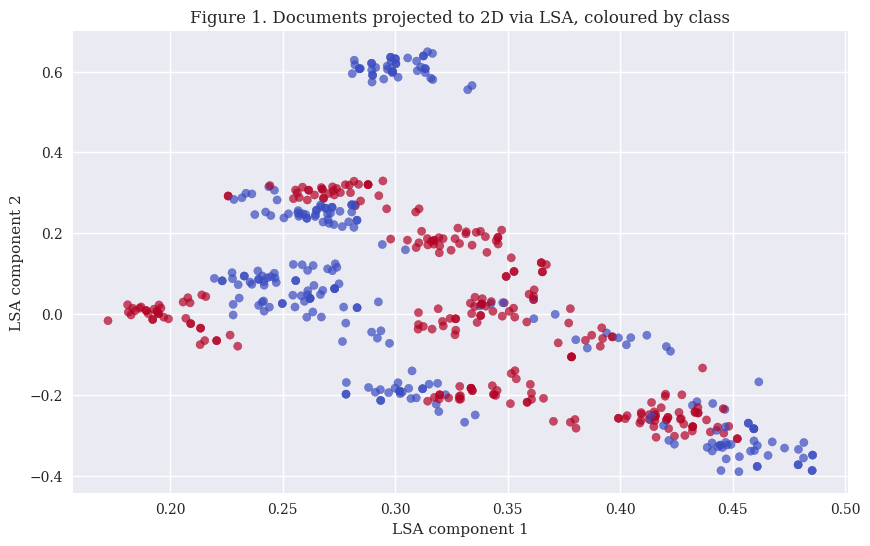

In [56]:
from sklearn.decomposition import TruncatedSVD

svd = TruncatedSVD(n_components=2, random_state=0)
coords = svd.fit_transform(X_tfidf)
plt.figure(figsize=(10, 6))
plt.scatter(coords[:, 0], coords[:, 1], c=y, cmap='coolwarm', s=35, alpha=0.7)
plt.title('Figure 1. Documents projected to 2D via LSA, coloured by class')
plt.xlabel('LSA component 1'); plt.ylabel('LSA component 2');

## Framework 4 — Distributional Semantics and Word Embeddings
"You shall know a word by the company it keeps" (Firth, 1957). Embeddings map each word to a dense vector
$v_w\in\mathbb{R}^d$, with $d\ll|V|$, so that words in similar contexts get similar vectors. A lightweight, fully local way to obtain
embeddings is Latent Semantic Analysis: factorise the term-document matrix and read word vectors from the
term factors. (word2vec/GloVe give similar geometry via a learned objective.)


In [57]:
# LSA word vectors: SVD of the (terms x documents) TF-IDF matrix.
svd_words = TruncatedSVD(n_components=50, random_state=0)
doc_topics = svd_words.fit_transform(X_tfidf)          # documents in topic space
word_vectors = svd_words.components_.T                 # |V| x 50 word vectors
word_index = {w: i for i, w in enumerate(feature_names)}
word_vectors.shape

(72, 50)

Every row of `word_vectors` is a dense, $d=50$-dimensional embedding of one vocabulary term. The head below
shows the first five coordinates for a handful of finance words — unlike the sparse one-hot columns of TF-IDF,
these are dense and semantically arranged, so nearby vectors mean related words.


In [58]:
# First five embedding dimensions for a few terms.
peek = [w for w in ['guidance', 'loss', 'growth', 'profit', 'demand']
        if w in word_index]
pd.DataFrame(np.round(word_vectors[[word_index[w] for w in peek], :5], 3),
            index=peek,
            columns=[f'dim{i}' for i in range(5)])

,dim0,dim1,dim2,dim3,dim4
guidance,0.217,-0.049,0.038,0.161,-0.020
loss,0.102,0.008,0.080,0.194,-0.141
profit,0.155,0.053,-0.004,0.103,0.221
demand,0.303,-0.234,-0.058,-0.041,-0.059


In [59]:
def most_similar(word, topn=5):
    if word not in word_index:
        return f"'{word}' not in vocabulary"
    v = word_vectors[word_index[word]]
    sims = word_vectors @ v / (np.linalg.norm(word_vectors, axis=1)
                                * np.linalg.norm(v) + 1e-9)
    order = np.argsort(-sims)
    return [(feature_names[i], round(float(sims[i]), 3))
            for i in order if feature_names[i] != word][:topn]

for w in ['guidance', 'loss', 'growth']:
    if w in word_index:
        print(f'{w:>10} ~ {most_similar(w)}')

  guidance ~ [('impairment', 0.0), ('cut', 0.0), ('cash', 0.0), ('analysts', 0.0), ('upgraded', 0.0)]
      loss ~ [('rose', 0.296), ('despite', 0.272), ('robust', 0.211), ('impairment', 0.196), ('widening', 0.174)]


## Framework 5 — Sequence Models: RNNs and LSTMs
**Why order matters, and where the gradient trouble comes from**
Bag-of-words and TF-IDF throw away word order, so "strong, not weak" and "weak, not strong" collapse to the
same vector. A recurrent network instead reads one token at a time, carrying a hidden state $h_t=\phi(W_h
h_{t-1}+W_x x_t+b)$, so $h_t$ depends on *everything seen so far, in order*. The **forward** pass looks harmless —
just the same affine map plus a $\tanh$, re-applied once per token.

The difficulty appears only in the backward pass. To learn, we need how the loss at the end of the sequence
depends on an early hidden state, and the chain rule forces that gradient to travel back through every
intermediate step: $\frac{\partial h_T}{\partial h_0}=J_TJ_{T-1}\cdots J_1,\qquad J_t=\frac{\partial h_t}{\partial h_{t-1}}=\operatorname{diag}(\phi'(\cdot))W_h$. So the gradient is a
**product of T Jacobians** — nothing in the *forward* formula multiplies, but composing the same map T
times and differentiating it *does*. The growth of such a product is governed by the dominant **singular
value** $\sigma_{\max}(J)$: roughly $\lVert J^T\rVert\approx\sigma_{\max}(J)^T$. If $\sigma_{\max}<1$ the
signal **vanishes** exponentially; if $\sigma_{\max}>1$ it explodes. We show this numerically (no
deep-learning library required).


In [60]:
def jacobian_norm(top_sv, steps):
    """Norm of J^steps for a matrix whose dominant singular value is top_sv."""
    rng = np.random.default_rng(1)
    A = rng.normal(size=(5, 5))
    U, _, Vt = np.linalg.svd(A)
    s = np.linspace(top_sv, top_sv * 0.3, 5)
    J = U @ np.diag(s) @ Vt
    return np.linalg.norm(np.linalg.matrix_power(J, steps))

print(f"{'dominant sv':>12} | {'||J^1||':>8} {'||J^10||':>10} {'||J^40||':>12}")
for sv in (0.7, 1.0, 1.3):
    print(f'{sv:>12} | {jacobian_norm(sv,1):>8.2f} '
            f'{jacobian_norm(sv,10):>10.3g} {jacobian_norm(sv,40):>12.3g}')

 dominant sv |  ||J^1||   ||J^10||     ||J^40||
         0.7 |     1.09    0.00627     3.07e-10
         1.0 |     1.56      0.222     0.000482
         1.3 |     2.02       3.06         17.4


**The LSTM: a learned, data-dependent memory**
The LSTM keeps a second state — the cell state $c_t$ (the long-term memory) — and updates it additively:
$c_t=f_t\odot c_{t-1}+i_t\odot g_t$. Three sigmoid **gates** in $(0,1)$ control the flow, computed from the previous
output $h_{t-1}$ and the current token $x_t$:

 • forget gate $f_t$ — how much of the old long-term memory $c_{t-1}$ to keep,
 • input gate $i_t$ — how much of the new candidate $g_t=\tanh(\cdot)$ to write,
 • output gate $o_t$ — how much of the cell to expose as the short-term,
working memory (the hidden state) $h_t=o_t\odot\tanh(c_t)$.

That is literally the name: $c$ is the long-term store, and $h=o\odot\tanh(c)$ is the short-term working readout —
"Long Short-Term Memory".

**An honest caveat.** The LSTM does not magically eliminate multiplicative gradients — backpropagating the
cell path still gives $\frac{\partial c_T}{\partial c_0}=\prod_{t=1}^{T}f_t$, a product of forget gates, which also shrinks if the $f_t$ are small. The real wins
are: (i) each $f_t\in(0,1)$ elementwise, so the cell path cannot explode the way a matrix with $\sigma_{\max}>1$ does; and (ii)
the decay rate is learned and per-dimension — the network can push $f_t\approx1$ on the exact dimensions that must
carry a fact across many tokens (e.g. holding "not" until it can flip a later word), instead of being stuck with one
fixed $\sigma_{\max}$ for every step. It is a powerful mitigation, not a cure — which is partly why attention (Framework
6) later replaced recurrence altogether.

Below, a single LSTM cell step in pure NumPy (with optional gate biases, used later to initialise the forget gate
near 1 so memory is retained by default).


In [61]:
def sigmoid(x): return 1 / (1 + np.exp(-np.clip(x, -30, 30)))

def lstm_step(x, h, c, W, b=None):
    if b is None:
        b = {k: 0.0 for k in 'fioc'}
    z = np.concatenate([h, x])
    f = sigmoid(W['f'] @ z + b['f'])              # forget gate: keep how much of old c?
    i = sigmoid(W['i'] @ z + b['i'])              # input gate: write how much of g?
    o = sigmoid(W['o'] @ z + b['o'])              # output gate: expose how much of c?
    g = np.tanh(W['c'] @ z + b['c'])              # candidate new content
    c_new = f * c + i * g                         # additive long-term memory path
    h_new = o * np.tanh(c_new)                    # short-term / working readout
    return h_new, c_new, f

rng = np.random.default_rng(2)
dh, dx = 3, 2
W = {k: rng.normal(scale=0.5, size=(dh, dh + dx)) for k in 'fioc'}
h, c = np.zeros(dh), np.zeros(dh)
for t, x in enumerate([np.array([1., 0]), np.array([0., 1]), np.array([1., 1])]):
    h, c, f = lstm_step(x, h, c, W)
    print(f't={t} forget-gate={np.round(f,2)} cell={np.round(c,2)}')

t=0 forget-gate=[0.23 0.54 0.4 ] cell=[-0.38  0.3  -0.04]
t=1 forget-gate=[0.7  0.4  0.53] cell=[-0.1   0.07 -0.14]
t=2 forget-gate=[0.42 0.45 0.45] cell=[-0.21  0.26 -0.15]


**Running an RNN and an LSTM on our financial headlines**
So far the toy loop used made-up 2-D inputs. Now we wire the recurrence to the actual corpus. Each headline
becomes a sequence of word vectors: we tokenise it and look up each in-vocabulary token's 50-dimensional
LSA embedding from Framework 4. So here a timestep is one word, and each document is its own sequence
fed through a fresh initial state h0=c0=0 — exactly the granularity clarified above (the recurrence runs within a
document, across its words).


In [62]:
def doc_to_sequence(doc, max_len=24):
    # Tokens that survived the TF-IDF vocabulary, mapped to LSA word vectors.
    toks = [t for t in doc.lower().split() if t in word_index]
    vecs = [word_vectors[word_index[t]] for t in toks[:max_len]]
    return np.array(vecs) if vecs else np.zeros((1, word_vectors.shape[1]))

lengths = np.array([len(doc_to_sequence(t)) for t in texts])
example = doc_to_sequence(texts[0])
print(f'embedding dim per token : {word_vectors.shape[1]}')
print(f'sequence length (words) : min {lengths.min()}, '
        f'mean {lengths.mean():.1f}, max {lengths.max()}')
print(f'document 0 -> sequence shape {example.shape} "{texts[0][:60]}"')

embedding dim per token : 50
sequence length (words) : min 6, mean 7.0, max 9
document 0 -> sequence shape (7, 50) "Daimler cut its outlook as orders declined sharply this quar"


Both encoders read a sequence and return a single fixed-length document vector by mean-pooling the hidden
states over time (a robust readout). We use fixed, sensibly-scaled random recurrent weights — a "reservoir" /
echo-state encoder — so the example stays dependency-free and runs anywhere; a production LSTM would
train these weights end-to-end with backprop-through-time. The RNN's recurrent matrix is scaled to spectral
radius 0.9 (just below the explosion threshold discussed above), and the LSTM's forget-gate bias is initialised
positive so the cell retains memory by default.


In [63]:
D = word_vectors.shape[1]           # token embedding dim (50)
Hdim = 64                           # recurrent hidden width

def make_rnn(seed=7):
    r = np.random.default_rng(seed)
    Wx = r.normal(scale=0.5, size=(Hdim, D))
    Wh = r.normal(scale=1.0, size=(Hdim, Hdim))
    Wh *= 0.9 / max(abs(np.linalg.eigvals(Wh)))             # spectral radius -> 0.9
    return Wx, Wh, np.zeros(Hdim)

def rnn_encode(seq, params):
    Wx, Wh, b = params
    h = np.zeros(Hdim); states = []
    for x in seq:
        h = np.tanh(Wx @ x + Wh @ h + b)                    # multiplicative recurrence
        states.append(h)
    return np.mean(states, axis=0)                          # mean-pooled document vector

def make_lstm(seed=11):
    r = np.random.default_rng(seed)
    W = {k: r.normal(scale=0.5, size=(Hdim, Hdim + D)) for k in 'fioc'}
    b = {'f': 1.5, 'i': 0.0, 'o': 0.0, 'c': 0.0}    # forget bias high -> retain
    return W, b

def lstm_encode(seq, params):
    W, b = params
    h = np.zeros(Hdim); c = np.zeros(Hdim); states = []
    for x in seq:
        h, c, _ = lstm_step(x, h, c, W, b)          # additive cell path
        states.append(h)
    return np.mean(states, axis=0)

rnn_params, lstm_params = make_rnn(), make_lstm()
print('RNN hidden state dim:', rnn_encode(example, rnn_params).shape)
print('LSTM hidden state dim:', lstm_encode(example, lstm_params).shape)

RNN hidden state dim: (64,)
LSTM hidden state dim: (64,)


We encode every document with each recurrent model, then — exactly as the book stacks a simple classifier on
learned features — fit a logistic-regression readout on the pooled states and compare held-out accuracy
against the earlier TF-IDF baseline. (Because the recurrent weights here are untrained, we expect the
bag-of-words baseline to remain competitive; the point is that the sequence encoders are order-aware and fully
runnable.)


In [64]:
from sklearn.linear_model import LogisticRegression as _LR
from sklearn.model_selection import cross_val_score

# Build the document-feature matrices from the two recurrent encoders.
R = np.vstack([rnn_encode(doc_to_sequence(t), rnn_params) for t in texts])
L = np.vstack([lstm_encode(doc_to_sequence(t), lstm_params) for t in texts])

def cv_acc(X):
    return cross_val_score(_LR(max_iter=2000), X, y, cv=5).mean()

seq_results = pd.DataFrame({
    'encoder': ['TF-IDF (bag of words)', 'RNN (reservoir) + LR',
                'LSTM (reservoir) + LR'],
    'features': [X_tfidf.shape[1], R.shape[1], L.shape[1]],
    'cv_accuracy': [round(cv_acc(X_tfidf), 3), round(cv_acc(R), 3),
                    round(cv_acc(L), 3)],
    'order_aware': [False, True, True],
})
seq_results

,encoder,features,cv_accuracy,order_aware
0,TF-IDF (bag of words),72,0.931,False
1,RNN (reservoir) + LR,64,0.935,True
2,LSTM (reservoir) + LR,64,0.838,True


**Watching the gradient vanish on a real sequence**
Finally, the intuition made visual. For a long sequence of word embeddings we propagate a gradient signal
backwards and track how much of it survives after k steps — for the RNN this is biglVert∏ JtbigrVert (product
of Jacobians), for the LSTM it is biglVert∏ ftbigrVert (product of forget gates). The RNN signal decays fast;
the LSTM — with its forget gate biased toward 1 — retains gradient far longer, which is precisely why it can
learn long-range dependencies that a vanilla RNN cannot.


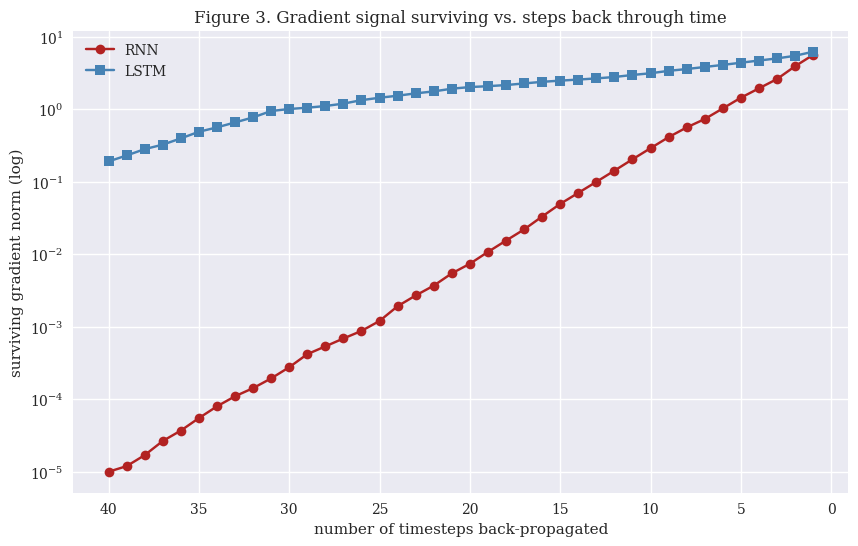

In [66]:
# Build one long sequence (40 tokens) by sampling real word embeddings.
rs = np.random.default_rng(3)
T = 40
long_seq = word_vectors[rs.integers(0, word_vectors.shape[0], size=T)]

# --- RNN: cumulative product of Jacobian norms, propagating from the end back ---
Wx, Wh, b = rnn_params
h = np.zeros(Hdim); hs = []
for x in long_seq:
    h = np.tanh(Wx @ x + Wh @ h + b); hs.append(h)
G = np.eye(Hdim); rnn_surv = []
for t in range(T - 1, -1, -1):
    J = (1 - hs[t] ** 2)[:, None] * Wh      # diag(tanh') @ Wh
    G = G @ J
    rnn_surv.append(np.linalg.norm(G))
rnn_surv = rnn_surv[::-1]

# --- LSTM: cumulative product of forget gates (the cell-path gradient) ---
W, bl = lstm_params
h = np.zeros(Hdim); c = np.zeros(Hdim); fs = []
for x in long_seq:
    h, c, f = lstm_step(x, h, c, W, bl); fs.append(f)
Gf = np.ones(Hdim); lstm_surv = []
for t in range(T - 1, -1, -1):
    Gf = Gf * fs[t]
    lstm_surv.append(np.linalg.norm(Gf))
lstm_surv = lstm_surv[::-1]

plt.figure(figsize=(10, 6))
steps_back = np.arange(T, 0, -1)
plt.semilogy(steps_back, rnn_surv, 'o-', label='RNN', color='firebrick')
plt.semilogy(steps_back, lstm_surv, 's-', label='LSTM', color='steelblue')
plt.gca().invert_xaxis()
plt.title('Figure 3. Gradient signal surviving vs. steps back through time')
plt.xlabel('number of timesteps back-propagated'); plt.ylabel('surviving gradient norm (log)')
plt.legend();

## Framework 6 — The Transformer: Attention
Attention lets every token interact with every other token directly. Each token emits a query $q$, key $k$ and value
$v$; the output is a content-weighted average

$\operatorname{Attention}(Q,K,V)=\operatorname{softmax}\left(\frac{QK^\top}{\sqrt{d_k}}\right)V$.

The $1/\sqrt{d_k}$ factor stops the softmax from saturating as dimension grows.


In [67]:
def softmax(x, axis=-1):
    x = x - x.max(axis=axis, keepdims=True)
    e = np.exp(x)
    return e / e.sum(axis=axis, keepdims=True)

def attention(Q, K, V, mask=None):
    dk = Q.shape[-1]
    scores = Q @ K.T / np.sqrt(dk)
    if mask is not None:
        scores = np.where(mask, scores, -1e9)
    A = softmax(scores)
    return A @ V, A

rng = np.random.default_rng(0)
n, d = 5, 8
X = rng.normal(size=(n, d))
Wq, Wk, Wv = (rng.normal(size=(d, d)) for _ in range(3))
out, A = attention(X @ Wq, X @ Wk, X @ Wv)
print('attention matrix (rows sum to 1):')
print(np.round(A, 2))

attention matrix (rows sum to 1):
[[0.01 0.   0.89 0.1  0.  ]
 [0.92 0.   0.   0.   0.08]
 [0.66 0.03 0.04 0.1  0.17]
 [0.21 0.05 0.26 0.01 0.47]
 [0.83 0.   0.05 0.   0.12]]


Reading the attention matrix as a labelled table makes its meaning clear: entry (i,j) is how much token i attends
to token j, and every row sums to 1 because of the softmax. In a real model these weights are how "not"
reaches back to flip the meaning of "strong" several positions away.


In [68]:
tokens = [f'tok{i}' for i in range(n)]
attn_df = pd.DataFrame(np.round(A, 2), index=tokens, columns=tokens)
attn_df['row_sum'] = attn_df.sum(axis=1).round(2)
attn_df

,tok0,tok1,tok2,tok3,tok4,row_sum
tok0,0.01,0.00,0.89,0.10,0.00,1.0
tok1,0.92,0.00,0.00,0.00,0.08,1.0
tok2,0.66,0.03,0.04,0.10,0.17,1.0
tok3,0.21,0.05,0.26,0.01,0.47,1.0
tok4,0.83,0.00,0.05,0.00,0.12,1.0


In [69]:
# Why the scaling matters: unscaled dot-products saturate the softmax at high d_k.
print(f"{'d_k':>5} | {'max prob unscaled':>18} {'max prob scaled':>16}")
for dk in (8, 64, 512):
    q = rng.normal(size=dk); ks = rng.normal(size=(6, dk))
    print(f'{dk:>5} | {softmax(ks @ q).max():>18.3f} '
            f'{softmax(ks @ q / np.sqrt(dk)).max():>16.3f}')

  d_k |  max prob unscaled  max prob scaled
    8 |              0.999            0.887
   64 |              0.984            0.355
  512 |              0.982            0.320


## Framework 7 — Pretrained Encoders: BERT, FinBERT and FinEAS
BERT is an encoder trained by masked language modelling: mask approximately $15\%$ of tokens and predict them from
both-sided context, $L_{\mathrm{MLM}}=-\sum_{i\in M}\log p(w_i\mid w_{\setminus M})$. The pooled [CLS] vector becomes a reusable
feature. FinBERT further-pretrains on financial text; FinEAS shapes the sentence geometry with a contrastive
loss

$L=yd^2+(1-y)\max(0,m-d)^2,\quad d=\lVert f(s_a)-f(s_b)\rVert_2$.

Without transformers installed we illustrate the contrastive idea with a frozen feature map; the code degrades
gracefully to real FinBERT if the library exists.


In [70]:
def contrastive_loss(za, zb, y, margin=1.0):
    d = np.linalg.norm(za - zb)
    return y * d**2 + (1 - y) * max(0.0, margin - d)**2, d

# Use our LSA document space as a stand-in sentence encoder.
def encode(doc):
    v = tfidf_vec.transform([doc])
    z = svd_words.transform(v).ravel()
    return z / (np.linalg.norm(z) + 1e-9)

pairs = [(texts[i], texts[j], int(y[i] == y[j])) for i, j in
        [(0, 1), (0, 2), (2, 3), (4, 5)]]
for a, b, lab in pairs:
    za, zb = encode(a), encode(b)
    loss, d = contrastive_loss(za, zb, lab, margin=1.0)
    print(f'[{"same" if lab else "diff":>4}] d={d:.2f} loss={loss:.2f}')

[same] d=1.41 loss=2.00
[diff] d=1.34 loss=0.00
[same] d=1.29 loss=1.66
[same] d=1.35 loss=1.83


## Framework 8 — Large Language Models
A language model $q$ is a compression scheme: cross-entropy $H(p,q)=\sum_x p(x)\log\frac{1}{q(x)}\ge H(p)$ is what training
minimises, and perplexity $\operatorname{PPL}=\exp(H)$ is its readable cousin. A decoder factorises text by the chain rule
$p(w_{1:T})=\prod_{t=1}^{T}p(w_t\mid w_{<t})$. We fit a small n-gram LM on our corpus and show that grammatical text gets lower
perplexity.


In [71]:
import math
from collections import defaultdict, Counter

class NGramLM:
    def __init__(self, n=3, k=0.1):
        self.n, self.k = n, k
        self.ctx = defaultdict(Counter); self.vocab = set()
    def fit(self, sentences):
        for s in sentences:
            toks = ['<s>'] * (self.n - 1) + s.lower().split() + ['</s>']
            self.vocab.update(toks)
            for i in range(self.n - 1, len(toks)):
                self.ctx[tuple(toks[i-self.n+1:i])][toks[i]] += 1
        return self
    def prob(self, w, context):
        c = self.ctx[tuple(context[-(self.n-1):])]
        return (c[w] + self.k) / (sum(c.values()) + self.k * len(self.vocab))
    def perplexity(self, s):
        toks = ['<s>'] * (self.n - 1) + s.lower().split() + ['</s>']
        lp = sum(math.log(self.prob(toks[i], toks[:i]))
                for i in range(self.n - 1, len(toks)))
        return math.exp(-lp / (len(toks) - self.n + 1))

lm = NGramLM(n=2, k=0.1).fit(texts)
good = texts[0]
bad = ' '.join(np.random.default_rng(0).permutation(texts[0].split()))
print(f'grammatical : ppl={lm.perplexity(good):7.1f} | {good[:60]}')
print(f'scrambled   : ppl={lm.perplexity(bad):7.1f} | {bad[:60]}')

grammatical : ppl=    3.2 | Daimler cut its outlook as orders declined sharply this quar
scrambled   : ppl=  836.6 | as declined its sharply outlook orders quarter Daimler this 


**Temperature: reshaping a real next-token distribution**
**What $T$ is.** Temperature is a single scalar knob that reshapes a probability distribution without changing which
outcomes are possible — only how concentrated the mass is:

$p_T(w)\propto p(w)^{1/T}$.

 • $T\to0^+$: the exponent $1/T\to\infty$, which crushes every probability except
the largest one, producing a one-hot greedy (arg-max) distribution.

 • $T=1$: the exponent is $1$, so the distribution is returned unchanged — the
model's native probabilities.

 • $T\to\infty$: the exponent $1/T\to0$ and $p(w)^0=1$ for every word, producing a
uniform (maximally random / "creative") distribution.

So $T<1$ sharpens the distribution (more deterministic) and $T>1$ flattens it (more diverse).

**How the next-token probabilities are computed.** We use the bigram `NGramLM.prob` with add-$k$ (Laplace)
smoothing. For a context word and a candidate next word w,

$P(w\mid\text{context})=\frac{\operatorname{count}(\text{context},w)+k}{\sum_{w'}\operatorname{count}(\text{context},w')+k|V|}$.

The $+k$ numerator and $+k|V|$ denominator give never-seen continuations a small nonzero probability (nothing
is impossible) and keep the vector normalised. We pick a real context (the first word of the first headline),
evaluate this over the entire vocabulary, and renormalise — so p below is the model's genuine belief about the
next token, not a hand-picked array.

**How the annealing is done.** `anneal` doesn't raise $p$ to the power $1/T$ directly — it uses the numerically stable,
mathematically equivalent softmax-with-temperature form:

 • $\operatorname{logits}=\log(p)/T$, so $\exp(\log(p)/T)=p^{1/T}$ — the temperature power computed
in log-space. The $+10^{-12}$ term avoids $\log(0)=-\infty$.

 • Subtracting $\max(\operatorname{logits})$ inside the exponential is the standard softmax stabilisation trick:
subtracting a constant from all logits scales numerator and denominator identically, leaving the result
unchanged while preventing overflow.

 • Dividing by the sum of exponentiated logits renormalises to a valid distribution — the "propto" in the
formula above.

 • the T == 0 branch is special-cased (because 1/T would divide by zero) and
short-circuits to the one-hot arg-max, the limit as $T\to0^+$.


In [74]:
def anneal(p, T):
    if T == 0:
        out = np.zeros_like(p); out[np.argmax(p)] = 1.0; return out
    logits = np.log(p + 1e-12) / T
    e = np.exp(logits - logits.max()); return e / e.sum()

# A real context from the corpus and the LM's real next-word distribution.
context = texts[0].lower().split()[:3]                 # one real preceding word
vocab = sorted(lm.vocab)
p = np.array([lm.prob(w, context) for w in vocab])
p = p / p.sum()                                         # renormalise over full vocab
print(f'context: {context!r} (|vocab|={len(vocab)})')

top = np.argsort(-p)[:6]
print(f"\n{'T':>5} | " + " ".join(f'{vocab[i]:>10}' for i in top))
for T in (0.0, 0.3, 0.7, 1.0, 2.0):
    a = anneal(p, T)
    print(f'{T:>5} | ' + " ".join(f'{a[i]:>10.3f}' for i in top))

context: ['daimler', 'cut', 'its'] (|vocab|=87)

    T |    outlook       </s>          a        <s>      after         an
  0.0 |      1.000      0.000      0.000      0.000      0.000      0.000
  0.3 |      1.000      0.000      0.000      0.000      0.000      0.000
  0.7 |      0.994      0.000      0.000      0.000      0.000      0.000
  1.0 |      0.908      0.001      0.001      0.001      0.001      0.001
  2.0 |      0.253      0.009      0.009      0.009      0.009      0.009


Two numbers make the sharpening/flattening concrete: the probability mass on the single most-likely word, and
the distribution's entropy $H(p_T)=-\sum_w p_T(w)\log p_T(w)$ (higher entropy means more uniform and more "surprising"
generations). Both move monotonically with T, and the plot shows the whole sweep rather than four
hand-picked points.


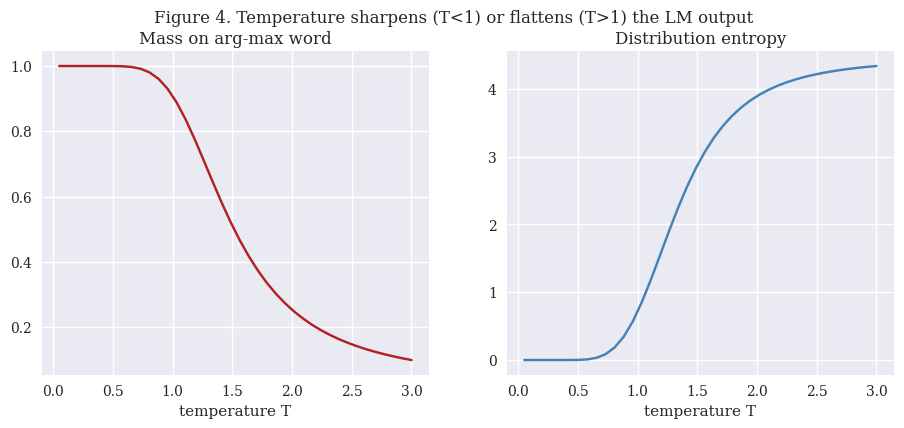

In [75]:
Ts = np.linspace(0.05, 3.0, 40)
top_mass, entropy = [], []
for T in Ts:
    a = anneal(p, T)
    top_mass.append(a.max())
    entropy.append(-(a * np.log(a + 1e-12)).sum())

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
axes[0].plot(Ts, top_mass, color='firebrick')
axes[0].set_title('Mass on arg-max word'); axes[0].set_xlabel('temperature T')
axes[1].plot(Ts, entropy, color='steelblue')
axes[1].set_title('Distribution entropy'); axes[1].set_xlabel('temperature T')
fig.suptitle('Figure 4. Temperature sharpens (T<1) or flattens (T>1) the LM output');

Finally, the reproducibility point made operational: sampling from the same annealed distribution with a fixed
seed is repeatable; without pinning temperature and seed, re-running a "backtested" LLM signal can silently
change its output, exactly the model-risk concern Framework 10 returns to.


In [76]:
rng_sample = np.random.default_rng(42)
for T in (0.2, 1.0, 2.0):
    a = anneal(p, T)
    draw = vocab[rng_sample.choice(len(vocab), p=a)]
    print(f'T={T:>4} -> sampled next word: {draw!r}')

T= 0.2 -> sampled next word: 'outlook'
T= 1.0 -> sampled next word: 'outlook'
T= 2.0 -> sampled next word: 'shrinking'


## Framework 9 — Quant Applications, Evaluation and Model Risk
Turning a text score into a strategy is a pipeline: $\text{text}\to s_{i,t}\to\operatorname{rank}\to w_t\to\text{net P\&L}$. The fatal error in finance is
look-ahead bias, not low accuracy. We show two things: how fitting an artefact on the full sample
manufactures a fake information coefficient, and how a signal's IC decays with horizon.


In [77]:
from scipy.stats import spearmanr

rng = np.random.default_rng(0)
n, k = 400, 50
fwd = rng.normal(size=n)                               # pure noise returns (no real edge)
candidates = rng.normal(size=(k, n))                   # 50 candidate text signals, all noise

# WRONG: search all candidates on the FULL sample and keep the best |IC|.
full_ics = np.array([abs(spearmanr(c, fwd).correlation) for c in candidates])
best = full_ics.argmax()
ic_leaked = spearmanr(candidates[best], fwd).correlation

# RIGHT: select on the train half, then evaluate the winner on untouched test.
tr, te = slice(0, n // 2), slice(n // 2, n)
train_ics = np.array([abs(spearmanr(c[tr], fwd[tr]).correlation) for c in candidates])
pick = train_ics.argmax()
ic_honest = spearmanr(candidates[pick][te], fwd[te]).correlation
print(f'leaked IC (best of {k} on full sample): {ic_leaked:+.3f} <- fake, selection bias')
print(f'honest IC (select on train, eval test): {ic_honest:+.3f} <- ~0, the truth')

leaked IC (best of 50 on full sample): -0.139 <- fake, selection bias
honest IC (select on train, eval test): -0.049 <- ~0, the truth


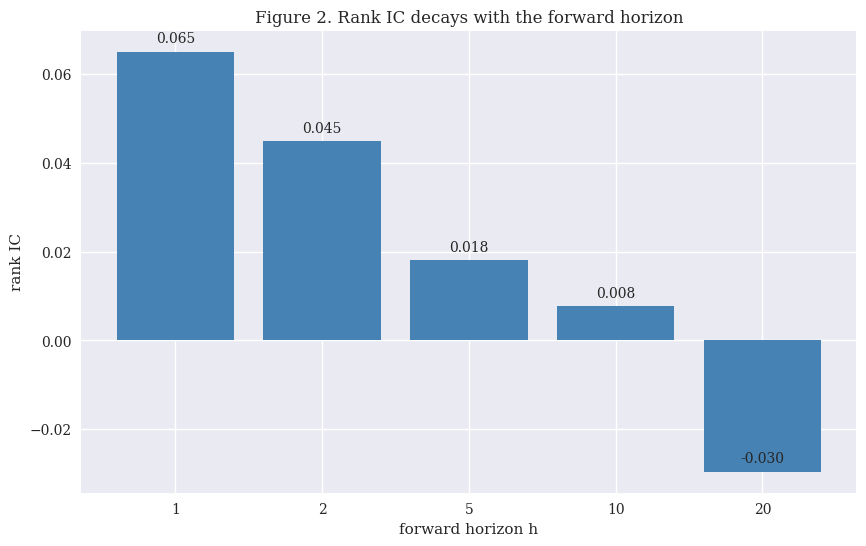

In [78]:
# IC decays with the forward horizon -> text signals have short half-lives.
sig = rng.normal(size=2000)
horizons = [1, 2, 5, 10, 20]
decays = [1.0, 0.6, 0.3, 0.1, 0.02]
ics = []
for h, dcy in zip(horizons, decays):
    ret = dcy * 0.05 * sig + rng.normal(size=2000)
    ics.append(spearmanr(sig, ret).correlation)

plt.figure(figsize=(10, 6))
plt.bar([str(h) for h in horizons], ics, color='steelblue')
plt.title('Figure 2. Rank IC decays with the forward horizon')
plt.xlabel('forward horizon h'); plt.ylabel('rank IC');
for i, v in enumerate(ics):
    plt.text(i, v + 0.002, f'{v:.3f}', ha='center')

**Takeaways**
 1. Representation is the throughline: counts → TF-IDF → embeddings →
contextual states → generative models.

 2. Newer is not automatically better: sparse baselines stay mandatory.
 3. Timing is the binding constraint: look-ahead bias has several
NLP-specific forms (document timing, fitted artefacts, pretraining, labels).

 4. Use LLMs to read and route; keep arithmetic and trading decisions in
deterministic, governed code.

Read widely. Model simply. Validate ruthlessly.
